# TP : Débruitage par filtre de Wiener

On utilise l'image Barbara pour la partie débruitage du TP (`M2AI_3_random.pdf`, pages 6 et 7). Les trois canaux de l'image sont identiques, donc on en garde un seul. On le convertit en flottants entre 0 et 1.

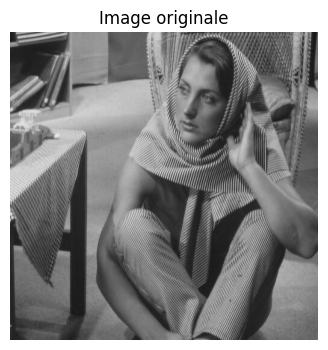

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

img = Image.open("data/barbara.jpg")
img = np.array(img, dtype=float)
img = img[:, :, 0] / 255


def show(image, title, interpolation=None):
    plt.imshow(image, cmap="gray", vmin=0, vmax=1, interpolation=interpolation)
    plt.title(title)
    plt.axis("off")


plt.figure(figsize=(4, 4))
show(img, "Image originale")
plt.show()

## 1. Ajout du bruit

On a $y=x+b$. Les pixels du bruit sont indépendants et suivent une loi $\mathcal N(0,\sigma^2)$.

Pour une image de $N$ pixels, la puissance est $P_x=\|x\|^2/N$. Le bruit a une puissance moyenne de $\sigma^2$. Pour avoir un SNR de $r$ dB, on choisit donc :

$$r=10\log_{10}\left(\frac{P_x}{\sigma^2}\right)
\quad\Longrightarrow\quad \sigma^2=P_x\,10^{-r/10}$$

On utilise le même tirage de bruit pour les cinq niveaux et on change seulement $\sigma$. Cela permet de comparer les résultats entre eux.

In [2]:
targets = [0, 5, 10, 15, 20]
np.random.seed(0)
noise = np.random.normal(0, 1, img.shape)
img_power = np.mean(img**2)

noisy_imgs = []
sigmas = []
for target in targets:
    sigma = np.sqrt(img_power / 10**(target / 10))
    noisy_imgs.append(img + sigma * noise)
    sigmas.append(sigma)

## 2. Filtre de Wiener

On note $X$ et $B$ les FFT2 (non normalisées) de $x$ et de $b$. Pour une image $n\times n$, avec $N=n^2$ :

$$B[k]=\sum_p b[p]\,e_k[p] \quad \text{avec} \quad e_k[p]=e^{-2i\pi(k_1p_1+k_2p_2)/n}$$

On a $|e_k[p]|=1$. De plus $\mathbb E[b[p]b[q]]=\sigma^2$ si $p=q$ et $0$ sinon, car les pixels sont indépendants. Donc :

$$\mathbb E|B[k]|^2=\sum_p\sum_q\mathbb E[b[p]b[q]]\,e_k[p]\,\overline{e_k[q]}=\sum_p\sigma^2|e_k[p]|^2=N\sigma^2$$

On fixe l'image propre et on fait la moyenne sur le bruit. On se place à une fréquence $k$ et on pose $A=|X[k]|^2$ et $C=N\sigma^2$. Avec un gain $g$, l'erreur vaut $(g-1)X+gB$. On note $R_k(g)$ l'erreur moyenne à la fréquence $k$ :

$$R_k(g)=\mathbb E|(g-1)X+gB|^2=|g-1|^2A+2\,\text{Re}\left((g-1)X\,\overline{g\,\mathbb E[B]}\right)+|g|^2C$$

Le terme du milieu est nul car $\mathbb E[B]=0$. Il reste $R_k(g)=|g-1|^2A+|g|^2C$. En complétant le carré :

$$R_k(g)=(A+C)\left|g-\frac{A}{A+C}\right|^2+\frac{AC}{A+C}$$

Comme $A+C>0$, le minimum est atteint pour $g=A/(A+C)$. On obtient donc le filtre :

$$H=\frac{|X|^2}{|X|^2+N\sigma^2}, \qquad \hat x=\text{IFFT2}(H\cdot\text{FFT2}(y))$$

Il faut encore vérifier que cela minimise l'erreur sur toute l'image. Pour des gains $g[k]$ quelconques, Parseval (avec une FFT non normalisée) donne :

$$\mathbb E\|\hat x-x\|^2=\frac1N\sum_k\mathbb E|g[k]Y[k]-X[k]|^2=\frac1N\sum_k R_k(g[k])$$

Chaque terme dépend seulement de son $g[k]$. La somme est donc minimale quand chaque terme est minimal, donc pour $g[k]=H[k]$. Multiplier chaque fréquence par un gain revient à faire une convolution circulaire. $H$ est donc bien le meilleur filtre $h$ tel que $\hat x=h*y$, comme dans le cours.

Ce filtre utilise l'image propre, c'est le filtre oracle du cours. On ne pourrait pas le calculer en pratique. Le passage par la FFT revient aussi à supposer que l'image est périodique.

In [3]:
power = np.abs(np.fft.fft2(img))**2
H_list = []
filtered_imgs = []
for noisy, sigma in zip(noisy_imgs, sigmas):
    H = power / (power + img.size * sigma**2)  # N * sigma**2 car la FFT n'est pas normalisée
    filtered = np.fft.ifft2(H * np.fft.fft2(noisy)).real
    H_list.append(H)
    filtered_imgs.append(filtered)

## 3. Résultats

On mesure le SNR avec la définition du cours :

$$SNR(z|x)=20\log_{10}\left(\frac{\|x\|}{\|z-x\|}\right)$$

On affiche toutes les images avec la même échelle de gris $[0,1]$ pour pouvoir les comparer

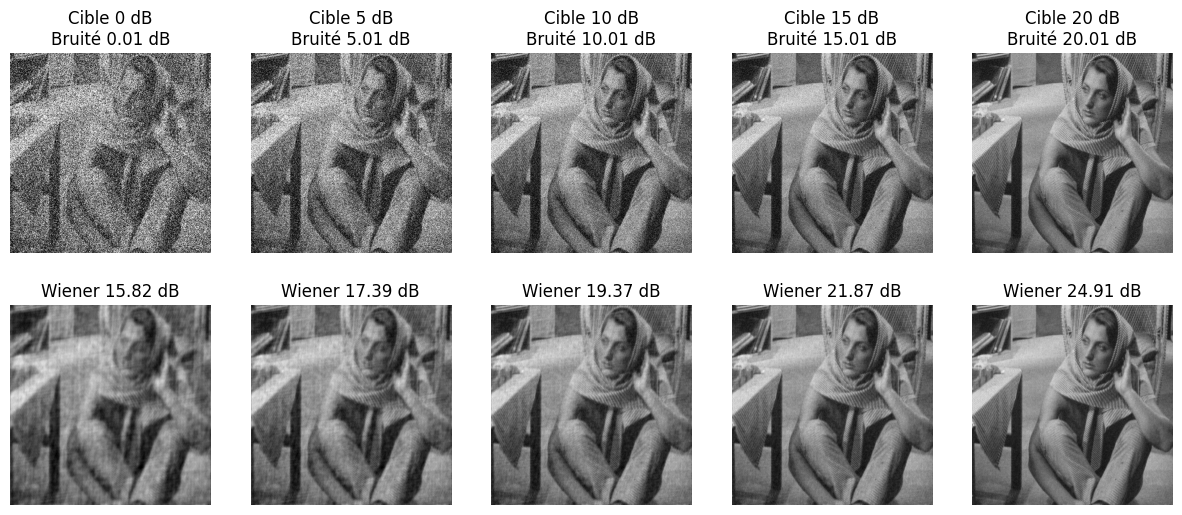

In [4]:
def snr(ref, result):
    return 20 * np.log10(np.linalg.norm(ref) / np.linalg.norm(result - ref))


plt.figure(figsize=(15, 6))
for i in range(5):
    plt.subplot(2, 5, i + 1)
    show(noisy_imgs[i], f"Cible {targets[i]} dB\nBruité {snr(img, noisy_imgs[i]):.2f} dB")
    plt.subplot(2, 5, i + 6)
    show(filtered_imgs[i], f"Wiener {snr(img, filtered_imgs[i]):.2f} dB")
plt.show()

Cible 0 dB : bruité 0.01 dB, Wiener 15.82 dB, amélioration 15.81 dB
Cible 5 dB : bruité 5.01 dB, Wiener 17.39 dB, amélioration 12.38 dB
Cible 10 dB : bruité 10.01 dB, Wiener 19.37 dB, amélioration 9.36 dB
Cible 15 dB : bruité 15.01 dB, Wiener 21.87 dB, amélioration 6.86 dB
Cible 20 dB : bruité 20.01 dB, Wiener 24.91 dB, amélioration 4.90 dB


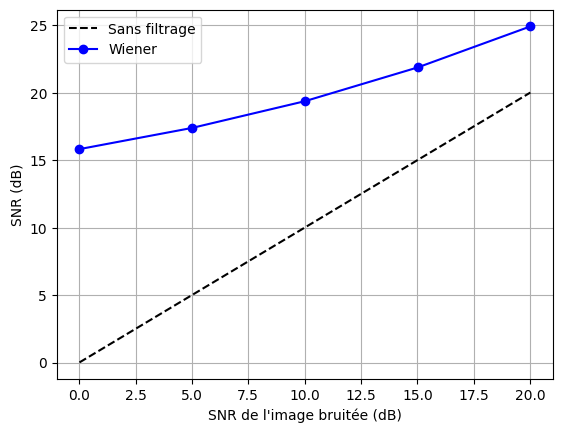

In [5]:
snr_noisy = [snr(img, noisy) for noisy in noisy_imgs]
snr_wiener = [snr(img, filtered) for filtered in filtered_imgs]

for i in range(5):
    print(f"Cible {targets[i]} dB : bruité {snr_noisy[i]:.2f} dB, Wiener {snr_wiener[i]:.2f} dB, amélioration {snr_wiener[i] - snr_noisy[i]:.2f} dB")

plt.plot(snr_noisy, snr_noisy, "k--", label="Sans filtrage")
plt.plot(snr_noisy, snr_wiener, "b-o", label="Wiener")
plt.xlabel("SNR de l'image bruitée (dB)")
plt.ylabel("SNR (dB)")
plt.legend()
plt.grid()
plt.show()

D'abord, les SNR des images bruitées sont à 0,01 dB des cibles. C'est normal car avec $512\times512$ pixels, la puissance du bruit tiré est très proche de $\sigma^2$. Le filtre améliore le SNR dans les cinq cas. La meilleure image est obtenue à 20 dB (24,9 dB), ce qui était attendu. Par contre, l'amélioration diminue quand le SNR augmente : on gagne 15,8 dB à 0 dB mais seulement 4,9 dB à 20 dB.

Pour comprendre pourquoi, on calcule l'erreur moyenne avec le filtre $H$. Dans la forme complétée de $R_k$, le premier terme s'annule pour $g=H[k]$. Il reste :

$$R_k(H[k])=\frac{AC}{A+C}=C\cdot\frac{A}{A+C}=N\sigma^2H[k]$$

On somme sur toutes les fréquences avec Parseval :

$$\mathbb E\|\hat x-x\|^2=\frac1N\sum_k R_k(H[k])=\frac1N\sum_k N\sigma^2H[k]=\sigma^2\sum_k H[k]$$

Le bruit a $N$ pixels de variance $\sigma^2$, donc $\mathbb E\|b\|^2=N\sigma^2$. On en déduit :

$$\frac{\mathbb E\|\hat x-x\|^2}{\mathbb E\|b\|^2}=\frac{\sigma^2\sum_k H[k]}{N\sigma^2}=\frac1N\sum_k H[k]$$

Quand $\sigma$ augmente, $C$ augmente, donc chaque $H[k]=A/(A+C)$ diminue et leur moyenne aussi. Après filtrage, il reste donc une plus petite part de l'erreur de départ. C'est pour cela que l'amélioration est plus grande à faible SNR.

On peut aussi prédire l'amélioration. Comme $y-x=b$ :

$$SNR(\hat x|x)-SNR(y|x)=20\log_{10}\left(\frac{\|b\|}{\|\hat x-x\|}\right)=10\log_{10}\left(\frac{\|b\|^2}{\|\hat x-x\|^2}\right)$$

Si on remplace les deux normes au carré par leurs moyennes, on trouve environ $-10\log_{10}\left(\frac1N\sum_k H[k]\right)$. On compare cette valeur aux mesures ci-dessous

In [6]:
for i in range(5):
    predicted = -10 * np.log10(np.mean(H_list[i]))
    measured = snr_wiener[i] - snr_noisy[i]
    print(f"Cible {targets[i]} dB : amélioration mesurée {measured:.2f} dB, prédite {predicted:.2f} dB")

Cible 0 dB : amélioration mesurée 15.81 dB, prédite 15.84 dB
Cible 5 dB : amélioration mesurée 12.38 dB, prédite 12.39 dB
Cible 10 dB : amélioration mesurée 9.36 dB, prédite 9.35 dB
Cible 15 dB : amélioration mesurée 6.86 dB, prédite 6.84 dB
Cible 20 dB : amélioration mesurée 4.90 dB, prédite 4.88 dB


La prédiction est à moins de 0,04 dB des mesures pour les cinq niveaux. C'est la loi des grands nombres : $\|b\|^2$ et $\|\hat x-x\|^2$ sont des sommes d'un très grand nombre de termes aléatoires, donc elles sont très proches de leurs moyennes

### Allure du filtre et perte de détails

On affiche $\log_{10}(H)$, sinon on ne verrait que les quelques fréquences où $H$ est proche de 1. On utilise fftshift pour mettre la fréquence nulle au centre, et la même échelle pour les trois niveaux de bruit

On a $H>1/2$ si et seulement si $2A>A+C$, donc si $A>C$, c'est-à-dire $|X|^2>N\sigma^2$. On calcule la proportion de ces fréquences. Ensuite on compare le meme détail du foulard, affiché sans lissage pour voir les vrais pixels

Cible 0 dB : H > 1/2 sur 0.7 % des fréquences
Cible 10 dB : H > 1/2 sur 6.7 % des fréquences
Cible 20 dB : H > 1/2 sur 30.9 % des fréquences


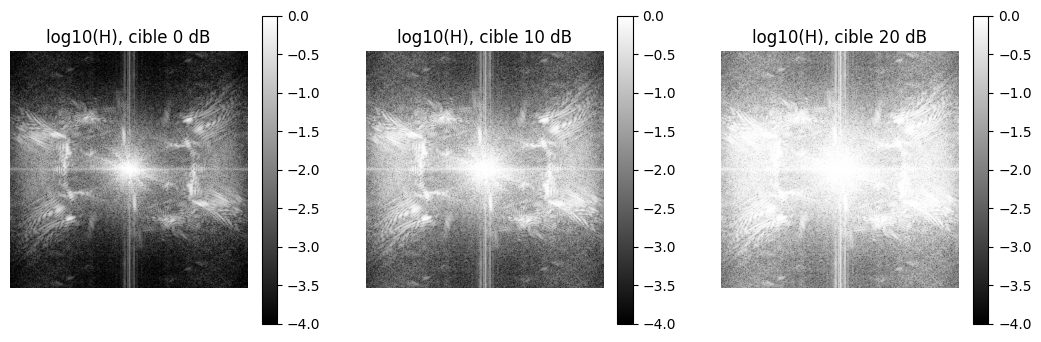

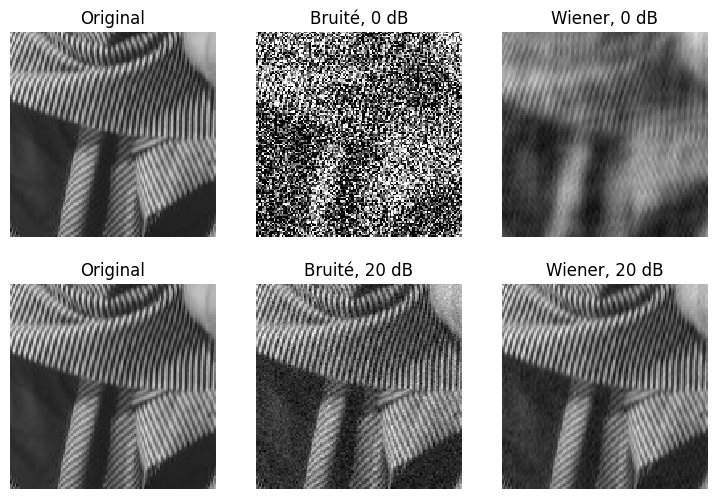

In [7]:
plt.figure(figsize=(13, 4))
for k, i in enumerate([0, 2, 4]):
    print(f"Cible {targets[i]} dB : H > 1/2 sur {100 * np.mean(H_list[i] > 0.5):.1f} % des fréquences")
    plt.subplot(1, 3, k + 1)
    plt.imshow(np.log10(np.fft.fftshift(H_list[i])), cmap="gray", vmin=-4, vmax=0)
    plt.colorbar()
    plt.title(f"log10(H), cible {targets[i]} dB")
    plt.axis("off")
plt.show()

plt.figure(figsize=(9, 6))
for row, i in enumerate([0, 4]):
    plt.subplot(2, 3, 3 * row + 1)
    show(img[200:328, 256:384], "Original", "nearest")
    plt.subplot(2, 3, 3 * row + 2)
    show(noisy_imgs[i][200:328, 256:384], f"Bruité, {targets[i]} dB", "nearest")
    plt.subplot(2, 3, 3 * row + 3)
    show(filtered_imgs[i][200:328, 256:384], f"Wiener, {targets[i]} dB", "nearest")
plt.show()

À 0 dB, $H$ dépasse $1/2$ pour seulement 0,7 % des fréquences, contre 30,9 % à 20 dB. Ailleurs $H\le1/2$, donc les amplitudes sont au moins divisées par 2. Sur les cartes, les fréquences gardées sont surtout au centre (basses fréquences). Il y a aussi quelques taches claires plus loin du centre, qui viennent probablement des rayures.

Sur le zoom, les rayures sont beaucoup moins nettes à 0 dB qu'à 20 dB. Cela vient de $H(X+B)=HX+HB$ : à chaque fréquence, le filtre atténue autant l'image que le bruit. Il ne peut donc pas enlever le bruit d'une fréquence sans enlever aussi l'image à cette fréquence. À 0 dB, la plupart des hautes fréquences, où sont les rayures, ont $H<1/2$, donc les rayures sont très atténuées